In [1]:
from perfetto.trace_processor import TraceProcessor
import pandas as pd


In [2]:
tp = TraceProcessor(trace='benchmark_merge_update_dense/test_update_insert_random_float_data.pftrace')

In [3]:
def time_for_merge_internal(tp):
    query = tp.query(
        "SELECT name, dur as dur_ns, dur / 1e9 as dur_s FROM slice WHERE name = 'merge_internal' ORDER BY ts"
    )
    merge_internal = query.as_pandas_dataframe().infer_objects()
    # The first run is a warmup drop it
    merge_internal = merge_internal.iloc[1:]
    display(merge_internal["dur_s"].describe())
    return merge_internal

In [4]:
time_for_merge_internal(tp)

count    10.000000
mean      1.585928
std       0.025629
min       1.551333
25%       1.562531
50%       1.588201
75%       1.610413
max       1.616428
Name: dur_s, dtype: float64

,name,dur_ns,dur_s
1,merge_internal,1614353098,1.614353
2,merge_internal,1558900446,1.558900
3,merge_internal,1573423543,1.573424
4,merge_internal,1551333333,1.551333
5,merge_internal,1582061770,1.582062
6,merge_internal,1554044303,1.554044
7,merge_internal,1594340470,1.594340
8,merge_internal,1600764858,1.600765
9,merge_internal,1616427650,1.616428
10,merge_internal,1613628585,1.613629


In [5]:
query = tp.query(
    "SELECT * FROM slice WHERE name = 'merge' ORDER BY ts"
)
query.as_pandas_dataframe().infer_objects()

,id,ts,dur,track_id,category,name,depth,parent_id,arg_set_id,thread_ts,thread_dur,thread_instruction_count,thread_instruction_delta,cat,slice_id
0,10,5078733744397,2375928,3,arcticdb.processing,merge,2,9,11,None,None,None,None,arcticdb.processing,10
1,11,5078736161978,3782648,3,arcticdb.processing,merge,2,9,12,None,None,None,None,arcticdb.processing,11
2,13,5078743165730,3919054,3,arcticdb.processing,merge,2,9,16,None,None,None,None,arcticdb.processing,13
3,18,5078747102709,3440089,3,arcticdb.processing,merge,2,9,18,None,None,None,None,arcticdb.processing,18
4,21,5078750562155,3117722,3,arcticdb.processing,merge,2,9,20,None,None,None,None,arcticdb.processing,21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12095,15406,5103960937110,4867026,18,arcticdb.processing,merge,2,15386,28,None,None,None,None,arcticdb.processing,15406
12096,15407,5103961449466,3832613,8,arcticdb.processing,merge,2,15379,30,None,None,None,None,arcticdb.processing,15407
12097,15408,5103965299856,3819652,8,arcticdb.processing,merge,2,15379,33,None,None,None,None,arcticdb.processing,15408
12098,15409,5103965820445,3675435,18,arcticdb.processing,merge,2,15386,30,None,None,None,None,arcticdb.processing,15409


# Merge update performance analysis

Suites:
* `baseline`: `ARCTICDB_MERGE_USE_ONLY_SPARSE_CODEPATH=OFF`, `ARCTICDB_MERGE_USE_WRITE_TO_SEGMENT_TASK=OFF`
* `sparse`: `ARCTICDB_MERGE_USE_ONLY_SPARSE_CODEPATH=ON`, `ARCTICDB_MERGE_USE_WRITE_TO_SEGMENT_TASK=OFF`
* `wtst_sparse`: both `ON`

Every trace holds 11 `merge_internal` slices. Run 0 is the warm-up and is dropped. Each slice is assigned to the run whose `merge_internal` interval contains it.

Slice hierarchy: `process` (one per target row slice, arg `rows`) → `match` / `update` / `update_and_insert` (depth 1) → per column `merge` / `merge_sparse` / `update` / `update_sparse` (depth 2, arg `column`). `merge_internal` is wall time. Sums of the other slices are CPU time summed over the worker threads.

In [6]:
import os
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 500)

SUITES = {
    "baseline": "benchmark_merge_update_dense",
    "sparse": "benchmark_merge_update_sparse_codepath_for_dense_data",
    "wtst_sparse": "benchmark_merge_update_write_to_segment_task_sparse_codepath",
}
TESTS = sorted(f.removesuffix(".pftrace") for f in os.listdir(SUITES["baseline"]) if f.endswith(".pftrace"))
UPDATE_TESTS = [t for t in TESTS if t.startswith("test_update_random")]
UPDATE_INSERT_TESTS = [t for t in TESTS if t not in UPDATE_TESTS]
ON_COLUMNS = [f"col_{i}" for i in range(5)]

SLICE_QUERY = """
SELECT s.ts, s.dur, s.name, s.depth, tt.utid,
       extract_arg(s.arg_set_id, 'debug.column') AS column,
       extract_arg(coalesce(p0.arg_set_id, p1.arg_set_id, s.arg_set_id), 'debug.rows') AS rows
FROM slice s
LEFT JOIN thread_track tt ON s.track_id = tt.id
LEFT JOIN slice p1 ON s.parent_id = p1.id
LEFT JOIN slice p0 ON p1.parent_id = p0.id
"""


def load_slices(path):
    trace = TraceProcessor(trace=path)
    try:
        df = trace.query(SLICE_QUERY).as_pandas_dataframe()
    finally:
        trace.close()
    df = df.infer_objects().astype({"ts": "int64", "dur": "int64", "depth": "int64"})
    df = df.sort_values("ts").reset_index(drop=True)
    runs = df[df["name"] == "merge_internal"][["ts", "dur"]].reset_index(drop=True)
    runs["run"] = runs.index
    runs["run_end"] = runs["ts"] + runs["dur"]
    df = pd.merge_asof(df, runs[["ts", "run", "run_end"]], on="ts", direction="backward")
    assert ((df["ts"] + df["dur"]) <= df["run_end"]).all(), f"Slice outside of merge_internal in {path}"
    return df[df["run"] > 0].drop(columns="run_end")


frames = []
for suite, directory in SUITES.items():
    for test in TESTS:
        df = load_slices(f"{directory}/{test}.pftrace")
        df["suite"] = suite
        df["test"] = test
        frames.append(df)
slices = pd.concat(frames, ignore_index=True)
slices["strategy"] = np.where(slices["test"].isin(UPDATE_TESTS), "update", "update_insert")
slices["dur_s"] = slices["dur"] / 1e9
assert (slices.groupby(["suite", "test"])["run"].nunique() == 10).all()

merge_internal = slices[slices["name"] == "merge_internal"].set_index(["test", "suite", "run"])["dur_s"].sort_index()
merge_internal.unstack("run").round(3)

run                                                       1        2        3        4        5        6        7        8        9        10
test                                    suite                                                                                                
test_one_index_value_float              baseline      32.557   33.656   32.868   33.445   33.444   33.354   32.860   33.336   33.425   32.998
                                        sparse        93.132   94.351   93.334   94.726   94.487   94.019   92.893   94.703   94.454   93.410
                                        wtst_sparse   94.017   94.022   93.597   95.014   93.894   95.230   94.060   93.853   93.858   93.965
test_one_index_value_per_segment_float  baseline       8.164    8.031    8.150    8.176    8.109    8.110    8.087    8.080    8.174    8.174
                                        sparse         8.512    7.950    7.993    7.936    7.507    7.714    7.434    7.452    8.084    8.024
                                        wtst_sparse    8.375    8.253    8.290    8.143    8.092    8.027    7.931    7.714    7.571    7.633
test_one_index_value_per_segment_string baseline     116.901  115.011  114.535  115.254  115.514  115.622  115.550  114.409  115.479  116.265
                                        sparse       329.534  330.824  328.904  331.585  331.767  328.720  331.889  329.018  328.736  332.157
                                        wtst_sparse   29.026   29.409   29.280   29.023   28.557   29.810   28.992   29.313   28.665   29.310
test_one_index_value_string             baseline     141.822  140.439  141.473  142.952  141.751  142.090  141.296  142.936  141.132  142.916
                                        sparse       418.623  415.338  417.036  418.507  416.434  418.984  420.874  420.619  419.863  416.142
                                        wtst_sparse  375.287  375.272  376.475  375.325  375.544  375.727  377.009  375.502  375.392  449.662
test_update_insert_random_float_data    baseline       1.614    1.559    1.573    1.551    1.582    1.554    1.594    1.601    1.616    1.614
                                        sparse         2.214    2.136    2.168    2.129    2.171    2.192    2.194    2.144    2.194    2.145
                                        wtst_sparse    2.199    2.139    2.117    2.153    2.153    2.146    2.147    2.161    2.138    2.136
test_update_insert_random_string_data   baseline       5.976    5.910    5.933    5.989    5.947    5.943    5.861    5.883    5.796    5.832
                                        sparse        19.747   19.626   20.339   19.913   19.625   19.724   19.794   19.781   19.632   19.839
                                        wtst_sparse    7.356    7.396    7.399    7.392    7.451    7.433    7.494    7.419    7.377    7.360
test_update_random_float_data           baseline       1.196    1.175    1.176    1.139    1.175    1.166    1.143    1.162    1.167    1.177
                                        sparse         1.539    1.542    1.614    1.554    1.516    1.522    1.580    1.550    1.511    1.533
                                        wtst_sparse    1.569    1.553    1.561    1.581    1.523    1.511    1.544    1.561    1.529    1.494
test_update_random_string_data          baseline       1.382    1.363    1.375    1.381    1.382    1.379    1.388    1.407    1.387    1.389
                                        sparse         2.022    2.056    2.091    2.043    2.018    2.094    2.053    2.044    2.076    2.067
                                        wtst_sparse    5.268    5.239    5.228    5.183    5.247    5.248    5.244    5.230    5.297    5.253

## Build sanity checks

Each suite's traces must contain the codepaths its build flags select:
* `baseline`: no `merge_sparse`, `update_sparse` or `WriteToSegmentTask`
* `sparse`: every per column slice is sparse (`ts` is the exception, it is always merged densely), no `WriteToSegmentTask`
* `wtst_sparse`: as `sparse`, plus exactly one `WriteToSegmentTask` per run

`run_benchmarks.sh` also writes the git state and the loaded `arcticdb_ext` to the top of each `log.txt`. All suites must come from the same source and from different extensions. Logs written before the header existed show it as not recorded.

In [7]:
per_column_slices = slices[slices["depth"] == 2]
data_column_slices = per_column_slices[per_column_slices["column"] != "ts"]
EXPECTED_PER_COLUMN = {
    ("baseline", "update"): {"update"},
    ("baseline", "update_insert"): {"merge"},
    ("sparse", "update"): {"update_sparse"},
    ("sparse", "update_insert"): {"merge_sparse"},
    ("wtst_sparse", "update"): {"update_sparse"},
    ("wtst_sparse", "update_insert"): {"merge_sparse"},
}
for (suite, strategy), names in data_column_slices.groupby(["suite", "strategy"])["name"]:
    assert set(names) == EXPECTED_PER_COLUMN[(suite, strategy)], f"{suite} {strategy}: {set(names)}"
assert (per_column_slices[per_column_slices["column"] == "ts"]["name"] == "merge").all()

write_to_segment_count = (
    slices[slices["name"] == "WriteToSegmentTask"]
    .groupby(["suite", "test", "run"])
    .size()
    .reindex(slices[["suite", "test", "run"]].drop_duplicates().set_index(["suite", "test", "run"]).index, fill_value=0)
)
assert (write_to_segment_count.drop("wtst_sparse", level="suite") == 0).all()
assert (write_to_segment_count.xs("wtst_sparse", level="suite") == 1).all()

slices.groupby(["suite", "strategy", "name"]).size().unstack("name", fill_value=0)

name                       WriteToSegmentTask  match  merge  merge_internal  merge_sparse  process  update  update_and_insert  update_sparse
suite       strategy                                                                                                                        
baseline    update                          0   2000      0              20             0     2000   22000                  0              0
            update_insert                   0   4020  44220              60             0     4020       0               4020              0
sparse      update                          0   2000      0              20             0     2000    2000                  0          20000
            update_insert                   0   4020   4020              60         40200     4020       0               4020              0
wtst_sparse update                         20   2000      0              20             0     2000    2000                  0          20000
            update_insert                  60   4020   4020              60         40200     4020       0               4020              0

In [8]:
PROVENANCE_KEYS = [
    "ARCTICDB_MERGE_USE_ONLY_SPARSE_CODEPATH",
    "ARCTICDB_MERGE_USE_WRITE_TO_SEGMENT_TASK",
    "git HEAD",
    "git diff HEAD sha256",
    "arcticdb_ext",
    "arcticdb_ext sha256",
]
EXPECTED_FLAGS = {"baseline": ("OFF", "OFF"), "sparse": ("ON", "OFF"), "wtst_sparse": ("ON", "ON")}


def read_provenance(directory):
    result = dict.fromkeys(PROVENANCE_KEYS)
    with open(f"{directory}/log.txt") as log:
        for line in log:
            if line.startswith("====="):
                break
            key, _, value = line.rstrip("\n").partition(": ")
            if key in result:
                result[key] = value
    return result


provenance = pd.DataFrame({suite: read_provenance(directory) for suite, directory in SUITES.items()}).T
recorded = provenance.dropna()
for suite, row in recorded.iterrows():
    flags = (row["ARCTICDB_MERGE_USE_ONLY_SPARSE_CODEPATH"], row["ARCTICDB_MERGE_USE_WRITE_TO_SEGMENT_TASK"])
    assert flags == EXPECTED_FLAGS[suite], f"{suite} was built with {flags}"
assert recorded["git HEAD"].nunique() <= 1, "Suites were built from different commits"
assert recorded["git diff HEAD sha256"].nunique() <= 1, "Suites were built from different uncommitted changes"
assert recorded["arcticdb_ext sha256"].is_unique, "Two suites loaded the same arcticdb_ext"
provenance.fillna("not recorded")

,ARCTICDB_MERGE_USE_ONLY_SPARSE_CODEPATH,ARCTICDB_MERGE_USE_WRITE_TO_SEGMENT_TASK,git HEAD,git diff HEAD sha256,arcticdb_ext,arcticdb_ext sha256
baseline,not recorded,not recorded,not recorded,not recorded,not recorded,not recorded
sparse,not recorded,not recorded,not recorded,not recorded,not recorded,not recorded
wtst_sparse,not recorded,not recorded,not recorded,not recorded,not recorded,not recorded


## Cost of the traced functions

Per run sum of each traced slice, then `describe()` over the 10 runs (seconds). Depth-1 `update` is the per row slice update, depth-2 `update` is the per column `update_column`.

In [9]:
slices["label"] = np.where((slices["depth"] == 2) & (slices["name"] == "update"), "update (column)", slices["name"])
per_run_cost = slices.groupby(["test", "suite", "label", "run"])["dur_s"].sum()
cost = per_run_cost.groupby(["test", "suite", "label"]).describe()
cost["share_of_merge_internal_%"] = (
    100 * cost["mean"] / cost.index.droplevel("label").map(merge_internal.groupby(["test", "suite"]).mean())
)
cost.round(4)

count       mean       std        min        25%        50%        75%        max  share_of_merge_internal_%
test                                    suite       label                                                                                                                           
test_one_index_value_float              baseline    match                10.0    31.9042    0.3439    31.2634    31.6178    32.0677    32.1404    32.3349                    96.1136
                                                    merge                10.0     0.0141    0.0002     0.0138     0.0139     0.0141     0.0142     0.0144                     0.0424
                                                    merge_internal       10.0    33.1942    0.3496    32.5567    32.9007    33.3448    33.4394    33.6557                   100.0000
                                                    process              10.0    31.9227    0.3431    31.2834    31.6358    32.0856    32.1581    32.3532                    96.1694
                                                    update_and_insert    10.0     0.0147    0.0012     0.0139     0.0141     0.0143     0.0144     0.0178                     0.0444
                                        sparse      match                10.0    90.2511    0.6690    89.2520    89.6880    90.4522    90.7597    91.0294                    96.0620
                                                    merge                10.0     0.0022    0.0001     0.0020     0.0021     0.0022     0.0022     0.0024                     0.0023
                                                    merge_internal       10.0    93.9509    0.6939    92.8934    93.3532    94.1849    94.4788    94.7259                   100.0000
                                                    merge_sparse         10.0     0.0722    0.0012     0.0704     0.0716     0.0722     0.0732     0.0737                     0.0768
                                                    process              10.0    90.3504    0.6831    89.3350    89.7714    90.5599    90.8815    91.1142                    96.1677
                                                    update_and_insert    10.0     0.0894    0.0246     0.0728     0.0742     0.0749     0.1085     0.1300                     0.0951
                                        wtst_sparse WriteToSegmentTask   10.0     0.0000    0.0000     0.0000     0.0000     0.0000     0.0000     0.0001                     0.0000
                                                    match                10.0    90.4152    0.4896    89.8601    90.1922    90.2240    90.3664    91.4312                    96.0321
                                                    merge                10.0     0.0022    0.0002     0.0020     0.0020     0.0022     0.0024     0.0025                     0.0024
                                                    merge_internal       10.0    94.1510    0.5307    93.5968    93.8671    93.9907    94.0507    95.2300                   100.0000
                                                    merge_sparse         10.0     0.0714    0.0005     0.0707     0.0710     0.0715     0.0717     0.0720                     0.0758
                                                    process              10.0    90.5028    0.4883    89.9432    90.2770    90.3213    90.4542    91.5155                    96.1252
                                                    update_and_insert    10.0     0.0781    0.0094     0.0730     0.0736     0.0743     0.0785     0.1035                     0.0829
test_one_index_value_per_segment_float  baseline    match                10.0   144.2254    1.0146   142.5870   143.4678   144.0716   145.0501   145.6178                  1775.0077
                                                    merge                10.0     3.1474    0.1945     2.8581     3.0232     3.1448     3.3175     3.4055                    38.7353
                                                    merge_internal       10.0     8.1253  

## Statistical comparison helper

For two sets of 10 `merge_internal` samples `a` (reference) and `b`:
* `ratio` = mean(b) / mean(a)
* Welch t-test p-value. `significant` means p < 0.05
* 95% bootstrap CI of the ratio of means (10 000 resamples)
* `verdict`: `within ±5%` when the CI is inside [0.95, 1.05]. Otherwise the change in % with its CI

In [10]:
RNG = np.random.default_rng(0)
N_BOOTSTRAP = 10_000


def bootstrap_ratio_ci(a, b):
    a_means = RNG.choice(a, size=(N_BOOTSTRAP, len(a))).mean(axis=1)
    b_means = RNG.choice(b, size=(N_BOOTSTRAP, len(b))).mean(axis=1)
    return np.percentile(b_means / a_means, [2.5, 97.5])


def compare(a, b):
    a, b = np.asarray(a), np.asarray(b)
    ratio = b.mean() / a.mean()
    p_value = stats.ttest_ind(b, a, equal_var=False).pvalue
    low, high = bootstrap_ratio_ci(a, b)
    if low >= 0.95 and high <= 1.05:
        verdict = "within ±5%"
    else:
        verdict = f"{100 * (ratio - 1):+.1f}% (CI {100 * (low - 1):+.1f}%..{100 * (high - 1):+.1f}%)"
    return {
        "ref_mean_s": a.mean(),
        "mean_s": b.mean(),
        "ratio": ratio,
        "ci_low": low,
        "ci_high": high,
        "p_value": p_value,
        "significant": p_value < 0.05,
        "verdict": verdict,
    }


def compare_suites(reference, other, tests):
    return pd.DataFrame(
        {test: compare(merge_internal.loc[test, reference], merge_internal.loc[test, other]) for test in tests}
    ).T


def describe_suites(tests, suites):
    df = merge_internal.loc[tests, suites].unstack("run").T.describe().T
    df["cv_%"] = 100 * df["std"] / df["mean"]
    return df

## Task 1: forced sparse codepath vs baseline

`merge_internal` per run, `baseline` vs `sparse`.

### update

In [11]:
describe_suites(UPDATE_TESTS, ["baseline", "sparse"]).round(4)

count    mean     std     min     25%     50%     75%     max    cv_%
test                           suite                                                                          
test_update_random_float_data  baseline   10.0  1.1675  0.0168  1.1391  1.1627  1.1709  1.1760  1.1957  1.4349
                               sparse     10.0  1.5461  0.0313  1.5108  1.5248  1.5408  1.5526  1.6145  2.0243
test_update_random_string_data baseline   10.0  1.3834  0.0111  1.3633  1.3794  1.3823  1.3878  1.4066  0.8022
                               sparse     10.0  2.0566  0.0260  2.0185  2.0437  2.0544  2.0740  2.0939  1.2648

In [12]:
compare_suites("baseline", "sparse", UPDATE_TESTS)

,ref_mean_s,mean_s,ratio,ci_low,ci_high,p_value,significant,verdict
test_update_random_float_data,1.167472,1.546098,1.324312,1.306293,1.344256,0.0,True,+32.4% (CI +30.6%..+34.4%)
test_update_random_string_data,1.383398,2.056583,1.486617,1.473517,1.49961,0.0,True,+48.7% (CI +47.4%..+50.0%)


### update_and_insert

In [13]:
describe_suites(UPDATE_INSERT_TESTS, ["baseline", "sparse"]).round(4)

count      mean     std       min       25%       50%       75%       max    cv_%
test                                    suite                                                                                      
test_one_index_value_float              baseline   10.0   33.1942  0.3496   32.5567   32.9007   33.3448   33.4394   33.6557  1.0531
                                        sparse     10.0   93.9509  0.6939   92.8934   93.3532   94.1849   94.4788   94.7259  0.7386
test_one_index_value_per_segment_float  baseline   10.0    8.1253  0.0499    8.0305    8.0926    8.1298    8.1711    8.1762  0.6145
                                        sparse     10.0    7.8606  0.3380    7.4344    7.5586    7.9427    8.0162    8.5125  4.2994
test_one_index_value_per_segment_string baseline   10.0  115.4540  0.7428  114.4086  115.0717  115.4967  115.6038  116.9011  0.6434
                                        sparse     10.0  330.3133  1.4595  328.7199  328.9327  330.1785  331.7214  332.1568  0.4418
test_one_index_value_string             baseline   10.0  141.8808  0.8527  140.4393  141.3399  141.7868  142.7097  142.9519  0.6010
                                        sparse     10.0  418.2418  1.9304  415.3375  416.5847  418.5648  419.6432  420.8737  0.4615
test_update_insert_random_float_data    baseline   10.0    1.5859  0.0256    1.5513    1.5625    1.5882    1.6104    1.6164  1.6160
                                        sparse     10.0    2.1687  0.0290    2.1295    2.1444    2.1692    2.1934    2.2139  1.3395
test_update_insert_random_string_data   baseline   10.0    5.9071  0.0630    5.7958    5.8668    5.9215    5.9463    5.9892  1.0670
                                        sparse     10.0   19.8020  0.2116   19.6250   19.6547   19.7644   19.8277   20.3391  1.0688

In [14]:
compare_suites("baseline", "sparse", UPDATE_INSERT_TESTS)

,ref_mean_s,mean_s,ratio,ci_low,ci_high,p_value,significant,verdict
test_one_index_value_float,33.194246,93.950856,2.830336,2.809819,2.851628,0.0,True,+183.0% (CI +181.0%..+185.2%)
test_one_index_value_per_segment_float,8.125342,7.860641,0.967423,0.943434,0.992414,0.035695,True,-3.3% (CI -5.7%..-0.8%)
test_one_index_value_per_segment_string,115.45396,330.313252,2.860995,2.847825,2.873651,0.0,True,+186.1% (CI +184.8%..+187.4%)
test_one_index_value_string,141.880765,418.241817,2.94784,2.934679,2.960812,0.0,True,+194.8% (CI +193.5%..+196.1%)
test_update_insert_random_float_data,1.585928,2.168748,1.367495,1.350924,1.384145,0.0,True,+36.7% (CI +35.1%..+38.4%)
test_update_insert_random_string_data,5.907119,19.801978,3.352223,3.324662,3.384605,0.0,True,+235.2% (CI +232.5%..+238.5%)


### Supporting context: per run sum of the processing slices

CPU time summed over threads, so it is not comparable to wall time. It shows how much of the slowdown comes from the column processing itself.

In [15]:
processing = slices[(slices["depth"] == 1) & slices["name"].isin(["update", "update_and_insert"])]
processing_per_run = processing.groupby(["test", "suite", "run"])["dur_s"].sum()
processing_ratio = pd.DataFrame(
    {
        test: compare(processing_per_run.loc[test, "baseline"], processing_per_run.loc[test, "sparse"])
        for test in TESTS
    }
).T
processing_ratio

,ref_mean_s,mean_s,ratio,ci_low,ci_high,p_value,significant,verdict
test_one_index_value_float,0.014734,0.089359,6.064848,5.120636,7.126408,0.000005,True,+506.5% (CI +412.1%..+612.6%)
test_one_index_value_per_segment_float,3.597704,10.078933,2.80149,2.601305,3.025766,0.0,True,+180.1% (CI +160.1%..+202.6%)
test_one_index_value_per_segment_string,1134.361582,3306.138754,2.914537,2.8272,3.010581,0.0,True,+191.5% (CI +182.7%..+201.1%)
test_one_index_value_string,0.053213,0.202539,3.806213,3.547696,4.095388,0.0,True,+280.6% (CI +254.8%..+309.5%)
test_update_insert_random_float_data,7.655642,18.203865,2.377837,2.301561,2.457403,0.0,True,+137.8% (CI +130.2%..+145.7%)
test_update_insert_random_string_data,105.869855,362.331761,3.422426,3.39234,3.453521,0.0,True,+242.2% (CI +239.2%..+245.4%)
test_update_random_float_data,1.693277,7.808861,4.611685,4.30651,4.906778,0.0,True,+361.2% (CI +330.7%..+390.7%)
test_update_random_string_data,13.656367,21.734354,1.591518,1.565736,1.618489,0.0,True,+59.2% (CI +56.6%..+61.8%)


## Task 2: WriteToSegmentTask + sparse codepath

`baseline` vs `wtst_sparse` gives the total effect. `sparse` vs `wtst_sparse` isolates the effect of converting the input with WriteToSegmentTask, since both use the sparse codepath.

In [16]:
describe_suites(TESTS, ["baseline", "sparse", "wtst_sparse"]).round(4)

count      mean      std       min       25%       50%       75%       max    cv_%
test                                    suite                                                                                          
test_one_index_value_float              baseline      10.0   33.1942   0.3496   32.5567   32.9007   33.3448   33.4394   33.6557  1.0531
                                        sparse        10.0   93.9509   0.6939   92.8934   93.3532   94.1849   94.4788   94.7259  0.7386
                                        wtst_sparse   10.0   94.1510   0.5307   93.5968   93.8671   93.9907   94.0507   95.2300  0.5637
test_one_index_value_per_segment_float  baseline      10.0    8.1253   0.0499    8.0305    8.0926    8.1298    8.1711    8.1762  0.6145
                                        sparse        10.0    7.8606   0.3380    7.4344    7.5586    7.9427    8.0162    8.5125  4.2994
                                        wtst_sparse   10.0    8.0030   0.2836    7.5706    7.7684    8.0593    8.2256    8.3751  3.5438
test_one_index_value_per_segment_string baseline      10.0  115.4540   0.7428  114.4086  115.0717  115.4967  115.6038  116.9011  0.6434
                                        sparse        10.0  330.3133   1.4595  328.7199  328.9327  330.1785  331.7214  332.1568  0.4418
                                        wtst_sparse   10.0   29.1384   0.3674   28.5570   28.9999   29.1529   29.3119   29.8102  1.2607
test_one_index_value_string             baseline      10.0  141.8808   0.8527  140.4393  141.3399  141.7868  142.7097  142.9519  0.6010
                                        sparse        10.0  418.2418   1.9304  415.3375  416.5847  418.5648  419.6432  420.8737  0.4615
                                        wtst_sparse   10.0  383.1194  23.3879  375.2725  375.3414  375.5228  376.2880  449.6624  6.1046
test_update_insert_random_float_data    baseline      10.0    1.5859   0.0256    1.5513    1.5625    1.5882    1.6104    1.6164  1.6160
                                        sparse        10.0    2.1687   0.0290    2.1295    2.1444    2.1692    2.1934    2.2139  1.3395
                                        wtst_sparse   10.0    2.1488   0.0213    2.1172    2.1383    2.1465    2.1528    2.1990  0.9910
test_update_insert_random_string_data   baseline      10.0    5.9071   0.0630    5.7958    5.8668    5.9215    5.9463    5.9892  1.0670
                                        sparse        10.0   19.8020   0.2116   19.6250   19.6547   19.7644   19.8277   20.3391  1.0688
                                        wtst_sparse   10.0    7.4077   0.0426    7.3565    7.3807    7.3974    7.4292    7.4940  0.5757
test_update_random_float_data           baseline      10.0    1.1675   0.0168    1.1391    1.1627    1.1709    1.1760    1.1957  1.4349
                                        sparse        10.0    1.5461   0.0313    1.5108    1.5248    1.5408    1.5526    1.6145  2.0243
                                        wtst_sparse   10.0    1.5426   0.0275    1.4943    1.5243    1.5486    1.5607    1.5809  1.7841
test_update_random_string_data          baseline      10.0    1.3834   0.0111    1.3633    1.3794    1.3823    1.3878    1.4066  0.8022
                                        sparse        10.0    2.0566   0.0260    2.0185    2.0437    2.0544    2.0740    2.0939  1.2648
                                        wtst_sparse   10.0    5.2437   0.0292    5.1826    5.2326    5.2456    5.2518    5.2965  0.5568

### baseline vs wtst_sparse

In [17]:
compare_suites("baseline", "wtst_sparse", TESTS)

,ref_mean_s,mean_s,ratio,ci_low,ci_high,p_value,significant,verdict
test_one_index_value_float,33.194246,94.150984,2.836365,2.817336,2.857434,0.0,True,+183.6% (CI +181.7%..+185.7%)
test_one_index_value_per_segment_float,8.125342,8.002973,0.98494,0.963858,1.005448,0.210054,False,within ±5%
test_one_index_value_per_segment_string,115.45396,29.138445,0.252382,0.250307,0.254465,0.0,True,-74.8% (CI -75.0%..-74.6%)
test_one_index_value_string,141.880765,383.119442,2.700292,2.640889,2.809224,0.0,True,+170.0% (CI +164.1%..+180.9%)
test_update_insert_random_float_data,1.585928,2.148813,1.354925,1.34031,1.370557,0.0,True,+35.5% (CI +34.0%..+37.1%)
test_update_insert_random_string_data,5.907119,7.407698,1.254029,1.245553,1.263307,0.0,True,+25.4% (CI +24.6%..+26.3%)
test_update_random_float_data,1.167472,1.542555,1.321278,1.303235,1.338781,0.0,True,+32.1% (CI +30.3%..+33.9%)
test_update_random_string_data,1.383398,5.243653,3.790415,3.768268,3.811609,0.0,True,+279.0% (CI +276.8%..+281.2%)


### sparse vs wtst_sparse

In [18]:
compare_suites("sparse", "wtst_sparse", TESTS)

,ref_mean_s,mean_s,ratio,ci_low,ci_high,p_value,significant,verdict
test_one_index_value_float,93.950856,94.150984,1.00213,0.99693,1.007756,0.478726,False,within ±5%
test_one_index_value_per_segment_float,7.860641,8.002973,1.018107,0.984761,1.051928,0.321563,False,+1.8% (CI -1.5%..+5.2%)
test_one_index_value_per_segment_string,330.313252,29.138445,0.088215,0.087511,0.088917,0.0,True,-91.2% (CI -91.2%..-91.1%)
test_one_index_value_string,418.241817,383.119442,0.916024,0.896405,0.952507,0.001031,True,-8.4% (CI -10.4%..-4.7%)
test_update_insert_random_float_data,2.168748,2.148813,0.990808,0.981477,1.000683,0.098645,False,within ±5%
test_update_insert_random_string_data,19.801978,7.407698,0.374089,0.371195,0.37654,0.0,True,-62.6% (CI -62.9%..-62.3%)
test_update_random_float_data,1.546098,1.542555,0.997708,0.981484,1.012971,0.791173,False,within ±5%
test_update_random_string_data,2.056583,5.243653,2.549692,2.529172,2.570006,0.0,True,+155.0% (CI +152.9%..+157.0%)


### WriteToSegmentTask duration and its share of merge_internal

In [19]:
write_to_segment = slices[(slices["suite"] == "wtst_sparse") & (slices["name"] == "WriteToSegmentTask")]
write_to_segment = write_to_segment.set_index(["test", "run"])["dur_s"]
assert write_to_segment.index.is_unique
write_to_segment_share = 100 * write_to_segment / merge_internal.xs("wtst_sparse", level="suite")
pd.concat(
    {
        "WriteToSegmentTask_s": write_to_segment.groupby("test").describe(),
        "share_of_merge_internal_%": write_to_segment_share.groupby("test").describe(),
    },
    axis=1,
).round(4)

WriteToSegmentTask_s                                                         share_of_merge_internal_%                                                              
                                                       count    mean     std     min     25%     50%     75%     max                     count     mean     std      min      25%      50%      75%      max
test                                                                                                                                                                                                        
test_one_index_value_float                              10.0  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0001                      10.0   0.0000  0.0000   0.0000   0.0000   0.0000   0.0001   0.0001
test_one_index_value_per_segment_float                  10.0  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0001                      10.0   0.0005  0.0001   0.0004   0.0004   0.0004   0.0005   0.0007
test_one_index_value_per_segment_string                 10.0  0.0539  0.0026  0.0507  0.0519  0.0535  0.0554  0.0581                      10.0   0.1850  0.0095   0.1732   0.1773   0.1833   0.1915   0.2019
test_one_index_value_string                             10.0  0.0563  0.0024  0.0534  0.0547  0.0562  0.0576  0.0613                      10.0   0.0147  0.0006   0.0136   0.0144   0.0148   0.0152   0.0154
test_update_insert_random_float_data                    10.0  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000  0.0000                      10.0   0.0016  0.0003   0.0015   0.0015   0.0015   0.0016   0.0021
test_update_insert_random_string_data                   10.0  4.2793  0.0460  4.2159  4.2541  4.2759  4.2838  4.3914                      10.0  57.7668  0.3726  57.3089  57.5092  57.7218  57.8696  58.5992
test_update_random_float_data                           10.0  0.0000  0.0000  0.0000  0.0000  0.0000  0.0001  0.0001                      10.0   0.0028  0.0008   0.0021   0.0022   0.0026   0.0033   0.0045
test_update_random_string_data                          10.0  3.3259  0.0174  3.3068  3.3089  3.3245  3.3427  3.3473                      10.0  63.4275  0.3113  63.0790  63.1493  63.4329  63.6205  63.9391

## Task 3: match

`match` runs once per target row slice. `test_one_index_value_*` has a single row slice so the per call and per run values coincide there.

### Per call

In [20]:
match = slices[slices["name"] == "match"]
match.groupby(["test", "suite"])["dur_s"].describe().round(5)

count       mean       std        min        25%        50%        75%        max
test                                    suite                                                                                          
test_one_index_value_float              baseline       10.0   31.90418   0.34389   31.26342   31.61775   32.06768   32.14037   32.33485
                                        sparse         10.0   90.25109   0.66900   89.25196   89.68798   90.45216   90.75968   91.02944
                                        wtst_sparse    10.0   90.41520   0.48957   89.86005   90.19217   90.22396   90.36643   91.43123
test_one_index_value_per_segment_float  baseline     1000.0    1.44225   0.58688    0.44378    1.00428    1.32809    1.80389    3.52832
                                        sparse       1000.0    1.24848   0.34835    0.64749    0.98833    1.15841    1.44956    3.36146
                                        wtst_sparse  1000.0    1.27929   0.34952    0.62382    0.99675    1.18420    1.54690    2.25134
test_one_index_value_per_segment_string baseline     1000.0   11.06795   6.40655    1.13255    5.53784   10.59269   16.41456   23.65063
                                        sparse       1000.0   32.40034  18.82852    3.26344   16.22161   32.48173   49.10590   66.50950
                                        wtst_sparse  1000.0    5.17609   0.41959    3.59440    4.89398    5.16518    5.46425    6.74303
test_one_index_value_string             baseline       10.0  140.61824   0.83393  139.19516  140.09611  140.53703  141.41630  141.67243
                                        sparse         10.0  414.43999   1.92197  411.54468  412.77256  414.77102  415.82678  417.03517
                                        wtst_sparse    10.0  379.19929  23.36396  371.34521  371.48128  371.62991  372.33893  445.67937
test_update_insert_random_float_data    baseline     1000.0    0.03875   0.02700    0.00833    0.01952    0.02956    0.04663    0.15489
                                        sparse       1000.0    0.04196   0.01977    0.01878    0.02372    0.03744    0.05269    0.12192
                                        wtst_sparse  1000.0    0.04151   0.01919    0.01584    0.02470    0.03807    0.05151    0.11593
test_update_insert_random_string_data   baseline     1000.0    0.02247   0.03203    0.00707    0.00777    0.00800    0.00974    0.14533
                                        sparse       1000.0    0.03252   0.02428    0.02027    0.02062    0.02121    0.02429    0.12955
                                        wtst_sparse  1000.0    0.04915   0.02289    0.02041    0.03219    0.04048    0.06111    0.14431
test_update_random_float_data           baseline     1000.0    0.03856   0.02264    0.00891    0.02003    0.03275    0.05137    0.16426
                                        sparse       1000.0    0.03810   0.02037    0.01342    0.02134    0.03076    0.04870    0.13284
                                        wtst_sparse  1000.0    0.03688   0.01872    0.01419    0.02152    0.03100    0.04630    0.12094
test_update_random_string_data          baseline     1000.0    0.06355   0.03530    0.01636    0.03533    0.05213    0.07967    0.20993
                                        sparse       1000.0    0.06789   0.02900    0.03156    0.04512    0.05514    0.08765    0.18474
                                        wtst_sparse  1000.0    0.05963   0.02593    0.02519    0.03904    0.04816    0.07562    0.15260

### Per run sum, with share of merge_internal (match is CPU time summed over threads)

In [21]:
match_per_run = match.groupby(["test", "suite", "run"])["dur_s"].sum()
match_summary = match_per_run.groupby(["test", "suite"]).describe()
match_summary["share_of_merge_internal_%"] = 100 * (match_per_run / merge_internal).groupby(["test", "suite"]).mean()
match_summary.round(4)

count       mean       std        min        25%        50%        75%        max  share_of_merge_internal_%
test                                    suite                                                                                                                    
test_one_index_value_float              baseline      10.0    31.9042    0.3439    31.2634    31.6178    32.0677    32.1404    32.3349                    96.1134
                                        sparse        10.0    90.2511    0.6690    89.2520    89.6880    90.4522    90.7597    91.0294                    96.0620
                                        wtst_sparse   10.0    90.4152    0.4896    89.8601    90.1922    90.2240    90.3664    91.4312                    96.0323
test_one_index_value_per_segment_float  baseline      10.0   144.2254    1.0146   142.5870   143.4678   144.0716   145.0501   145.6178                  1775.0113
                                        sparse        10.0   124.8477    5.1203   119.2321   120.9998   124.4491   127.1869   136.0334                  1588.9547
                                        wtst_sparse   10.0   127.9294    4.5690   122.0136   123.8067   128.4605   130.7204   135.9099                  1598.6966
test_one_index_value_per_segment_string baseline      10.0  1106.7952   41.0974  1022.4702  1093.5139  1109.1293  1119.5262  1187.3343                   958.6383
                                        sparse        10.0  3240.0343  123.3272  3010.0506  3149.6865  3266.0043  3314.8811  3410.4554                   981.0251
                                        wtst_sparse   10.0   517.6095    2.2489   512.9256   516.6215   517.9333   519.2013   520.4121                  1776.6781
test_one_index_value_string             baseline      10.0   140.6182    0.8339   139.1952   140.0961   140.5370   141.4163   141.6724                    99.1102
                                        sparse        10.0   414.4400    1.9220   411.5447   412.7726   414.7710   415.8268   417.0352                    99.0910
                                        wtst_sparse   10.0   379.1993   23.3640   371.3452   371.4813   371.6299   372.3389   445.6794                    98.9741
test_update_insert_random_float_data    baseline      10.0     3.8752    0.2601     3.5424     3.6946     3.8004     3.9812     4.3412                   244.2744
                                        sparse        10.0     4.1962    0.2754     3.7533     4.0554     4.1512     4.4021     4.6668                   193.5586
                                        wtst_sparse   10.0     4.1512    0.1939     3.8832     4.0231     4.1275     4.2678     4.4416                   193.2339
test_update_insert_random_string_data   baseline      10.0     2.2469    0.1847     1.9081     2.1388     2.2190     2.3790     2.5107                    38.0418
                                        sparse        10.0     3.2521    0.0934     3.1048     3.1778     3.2767     3.3020     3.3961                    16.4226
                                        wtst_sparse   10.0     4.9146    0.2104     4.7034     4.7507     4.8508     5.0784     5.3082                    66.3407
test_update_random_float_data           baseline      10.0     3.8555    0.1913     3.6350     3.7172     3.8096     4.0038     4.1642                   330.2192
                                        sparse        10.0     3.8101    0.1527     3.6050     3.7422     3.7797     3.9176     4.0416                   246.4821
                                        wtst_sparse   10.0     3.6877    0.2526     3.4675     3.5065     3.6334     3.6839     4.2688                   239.0926
test_update_random_string_data          baseline      10.0     6.3554    0.2573     5.9730     6.1204     6.4071     6.5671     6.6789                   459.4319
                                        sparse        10.0     6.7888    0.1618     6.5827     6.6752     6.7557     6.8567     7.1095                   330.1535
   

## Task 4: per column outliers

Per column slices are the depth-2 slices (`merge`, `merge_sparse`, `update`, `update_sparse`). Compared columns:
* update_and_insert tests: `ts` and `col_0`..`col_9`
* update tests: `col_5`..`col_9`. The `on` columns `col_0`..`col_4` keep the target values and take a different branch

A column is an outlier if its time is above Q3 + 1.5·IQR of the compared columns. `ratio_to_median` is its time divided by the median of the compared columns. Column `col_i` has `i·10%` NaN/None values.

In [22]:
per_column = slices[slices["depth"] == 2].copy()
per_column = per_column[
    (per_column["strategy"] == "update_insert")
    | ~per_column["column"].isin(ON_COLUMNS)
]
COLUMN_ORDER = ["ts"] + [f"col_{i}" for i in range(10)]
per_column["column"] = pd.Categorical(per_column["column"], categories=COLUMN_ORDER, ordered=True)
assert per_column.groupby(["suite", "test", "run", "rows", "column"], observed=True).size().eq(1).all()


def flag_outliers(df, group_keys):
    grouped = df.groupby(group_keys, observed=True)["dur_s"]
    q1 = grouped.transform(lambda x: x.quantile(0.25))
    q3 = grouped.transform(lambda x: x.quantile(0.75))
    df = df.assign(
        ratio_to_median=df["dur_s"] / grouped.transform("median"),
        is_outlier=df["dur_s"] > q3 + 1.5 * (q3 - q1),
        is_slowest=df["dur_s"] == grouped.transform("max"),
    )
    return df

### 4.1 Within each row slice

For each (suite, test, run, row slice), compare the columns. The table shows, per column, the % of row slices where it is an outlier, the % where it is the slowest, and its mean and max ratio to the row slice median.

In [23]:
segment_outliers = flag_outliers(per_column, ["suite", "test", "run", "rows"])
segment_summary = segment_outliers.groupby(["test", "suite", "column"], observed=True).agg(
    segments=("dur_s", "size"),
    outlier_pct=("is_outlier", lambda x: 100 * x.mean()),
    slowest_pct=("is_slowest", lambda x: 100 * x.mean()),
    mean_ratio_to_median=("ratio_to_median", "mean"),
    max_ratio_to_median=("ratio_to_median", "max"),
    mean_dur_ms=("dur_s", lambda x: 1000 * x.mean()),
)
segment_summary.round(3)

segments  outlier_pct  slowest_pct  mean_ratio_to_median  max_ratio_to_median  mean_dur_ms
test                                    suite       column                                                                                            
test_one_index_value_float              baseline    ts            10          0.0          0.0                 0.821                1.000        0.695
                                                    col_0         10          0.0          0.0                 0.921                0.996        0.780
                                                    col_1         10          0.0          0.0                 0.932                1.000        0.790
                                                    col_2         10          0.0          0.0                 0.934                0.979        0.791
                                                    col_3         10          0.0          0.0                 0.950                1.000        0.805
                                                    col_4         10          0.0          0.0                 0.968                1.000        0.820
                                                    col_5         10          0.0        100.0                 2.479                2.680        2.102
                                                    col_6         10          0.0          0.0                 2.272                2.449        1.926
                                                    col_7         10          0.0          0.0                 2.113                2.253        1.790
                                                    col_8         10          0.0          0.0                 2.125                2.223        1.800
                                                    col_9         10          0.0          0.0                 2.112                2.426        1.788
                                        sparse      ts            10          0.0          0.0                 0.393                0.425        2.187
                                                    col_0         10          0.0          0.0                 0.965                0.994        5.368
                                                    col_1         10          0.0          0.0                 0.988                1.000        5.497
                                                    col_2         10          0.0          0.0                 0.989                1.000        5.503
                                                    col_3         10          0.0          0.0                 0.987                1.000        5.495
                                                    col_4         10          0.0          0.0                 0.989                1.000        5.505
                                                    col_5         10          0.0         80.0                 1.656                1.778        9.216
                                                    col_6         10          0.0          0.0                 1.585                1.643        8.822
                                                    col_7         10          0.0         10.0                 1.605                1.659        8.935
                                                    col_8         10          0.0          0.0                 1.595                1.657        8.879
                                                    col_9         10          0.0         10.0                 1.611                1.663        8.968
                                        wtst_sparse ts            10          0.0          0.0                 0.407                0.466        2.233
                                                    col_0         10          0.0          0.0                 0.984                1.000        5.398
                                                    col_1         10          0.0          0.0                 0.981                1.

Worst individual outliers (top 20 by ratio to the row slice median):

In [24]:
segment_outliers[segment_outliers["is_outlier"]].nlargest(20, "ratio_to_median")[
    ["suite", "test", "run", "rows", "column", "name", "dur_s", "ratio_to_median"]
]

,suite,test,run,rows,column,name,dur_s,ratio_to_median
97118,sparse,test_one_index_value_per_segment_string,1,"[[3400000,3500000]]",col_0,merge_sparse,49.187289,3273.913907
108051,sparse,test_one_index_value_per_segment_string,9,"[[1600000,1700000]]",col_0,merge_sparse,58.893834,3037.433193
108871,sparse,test_one_index_value_per_segment_string,9,"[[5000000,5100000]]",col_8,merge_sparse,58.949853,3029.371717
106930,sparse,test_one_index_value_per_segment_string,8,"[[7200000,7300000]]",col_0,merge_sparse,58.757408,3018.689642
106933,sparse,test_one_index_value_per_segment_string,8,"[[6600000,6700000]]",col_0,merge_sparse,58.401977,3008.536571
103287,sparse,test_one_index_value_per_segment_string,5,"[[8800000,8900000]]",col_0,merge_sparse,56.002141,2875.248367
98248,sparse,test_one_index_value_per_segment_string,2,"[[1700000,1800000]]",col_0,merge_sparse,52.451064,2849.808149
103013,sparse,test_one_index_value_per_segment_string,5,"[[7900000,8000000]]",col_0,merge_sparse,55.440024,2839.873020
99654,sparse,test_one_index_value_per_segment_string,3,"[[5200000,5300000]]",col_0,merge_sparse,52.318370,2677.796237
105492,sparse,test_one_index_value_per_segment_string,7,"[[6700000,6800000]]",col_7,merge_sparse,56.235422,2673.724192


### 4.2 Total per column

Sum each column over all row slices in a run, then compare the columns' per run totals. `outlier_runs` counts the runs (out of 10) where the column total is a Tukey outlier among the columns.

In [25]:
column_totals = per_column.groupby(["suite", "test", "run", "column"], observed=True)["dur_s"].sum().reset_index()
column_totals = flag_outliers(column_totals, ["suite", "test", "run"])
total_summary = column_totals.groupby(["test", "suite", "column"], observed=True).agg(
    mean_total_s=("dur_s", "mean"),
    std_total_s=("dur_s", "std"),
    min_total_s=("dur_s", "min"),
    max_total_s=("dur_s", "max"),
    mean_ratio_to_median=("ratio_to_median", "mean"),
    outlier_runs=("is_outlier", "sum"),
)
total_summary.round(4)

mean_total_s  std_total_s  min_total_s  max_total_s  mean_ratio_to_median  outlier_runs
test                                    suite       column                                                                                         
test_one_index_value_float              baseline    ts            0.0007       0.0001       0.0006       0.0008                0.8211             0
                                                    col_0         0.0008       0.0000       0.0007       0.0008                0.9211             0
                                                    col_1         0.0008       0.0000       0.0007       0.0009                0.9320             0
                                                    col_2         0.0008       0.0000       0.0008       0.0008                0.9340             0
                                                    col_3         0.0008       0.0000       0.0008       0.0009                0.9502             0
                                                    col_4         0.0008       0.0000       0.0007       0.0009                0.9684             0
                                                    col_5         0.0021       0.0001       0.0019       0.0023                2.4794             0
                                                    col_6         0.0019       0.0001       0.0018       0.0022                2.2718             0
                                                    col_7         0.0018       0.0001       0.0017       0.0018                2.1132             0
                                                    col_8         0.0018       0.0001       0.0017       0.0019                2.1247             0
                                                    col_9         0.0018       0.0001       0.0017       0.0020                2.1120             0
                                        sparse      ts            0.0022       0.0001       0.0020       0.0024                0.3929             0
                                                    col_0         0.0054       0.0001       0.0052       0.0055                0.9647             0
                                                    col_1         0.0055       0.0001       0.0054       0.0057                0.9876             0
                                                    col_2         0.0055       0.0000       0.0055       0.0056                0.9889             0
                                                    col_3         0.0055       0.0001       0.0054       0.0056                0.9874             0
                                                    col_4         0.0055       0.0001       0.0055       0.0056                0.9893             0
                                                    col_5         0.0092       0.0003       0.0089       0.0098                1.6563             0
                                                    col_6         0.0088       0.0002       0.0086       0.0091                1.5853             0
                                                    col_7         0.0089       0.0003       0.0085       0.0093                1.6054             0
                                                    col_8         0.0089       0.0002       0.0084       0.0092                1.5955             0
                                                    col_9         0.0090       0.0002       0.0086       0.0092                1.6113             0
                                        wtst_sparse ts            0.0022       0.0002       0.0020       0.0025                0.4068             0
                                                    col_0         0.0054       0.0001       0.0052       0.0056                0.9836             0
                                                    col_1         0.0054       0.0000       0.0053       0.0055                0.9810             0
                                                    col_2       

### Impact of the NaN/None count

Spearman correlation between the NaN fraction of `col_i` (i·10%) and its mean total time. `ts` is excluded because it has no NaN values. The update tests only have 5 columns so their correlation is less reliable.

In [26]:
nan_impact = total_summary.reset_index()
nan_impact = nan_impact[nan_impact["column"] != "ts"]
nan_impact["nan_pct"] = nan_impact["column"].astype(str).str.removeprefix("col_").astype(int) * 10


def spearman(df):
    result = stats.spearmanr(df["nan_pct"], df["mean_total_s"])
    return pd.Series({"columns": len(df), "spearman_rho": result.statistic, "p_value": result.pvalue})


nan_impact.groupby(["test", "suite"])[["nan_pct", "mean_total_s"]].apply(spearman).round(4)

columns  spearman_rho  p_value
test                                    suite                                      
test_one_index_value_float              baseline        10.0        0.7697   0.0092
                                        sparse          10.0        0.8303   0.0029
                                        wtst_sparse     10.0        0.7818   0.0075
test_one_index_value_per_segment_float  baseline        10.0        0.2606   0.4671
                                        sparse          10.0        0.8182   0.0038
                                        wtst_sparse     10.0        0.8182   0.0038
test_one_index_value_per_segment_string baseline        10.0       -0.7818   0.0075
                                        sparse          10.0       -0.6606   0.0376
                                        wtst_sparse     10.0       -0.9879   0.0000
test_one_index_value_string             baseline        10.0       -0.7697   0.0092
                                        sparse          10.0       -0.6242   0.0537
                                        wtst_sparse     10.0       -0.6242   0.0537
test_update_insert_random_float_data    baseline        10.0        0.5273   0.1173
                                        sparse          10.0        0.0545   0.8810
                                        wtst_sparse     10.0        0.2242   0.5334
test_update_insert_random_string_data   baseline        10.0       -0.9515   0.0000
                                        sparse          10.0       -0.6727   0.0330
                                        wtst_sparse     10.0       -0.9879   0.0000
test_update_random_float_data           baseline         5.0       -1.0000   0.0000
                                        sparse           5.0       -1.0000   0.0000
                                        wtst_sparse      5.0       -1.0000   0.0000
test_update_random_string_data          baseline         5.0       -1.0000   0.0000
                                        sparse           5.0       -1.0000   0.0000
                                        wtst_sparse      5.0       -1.0000   0.0000

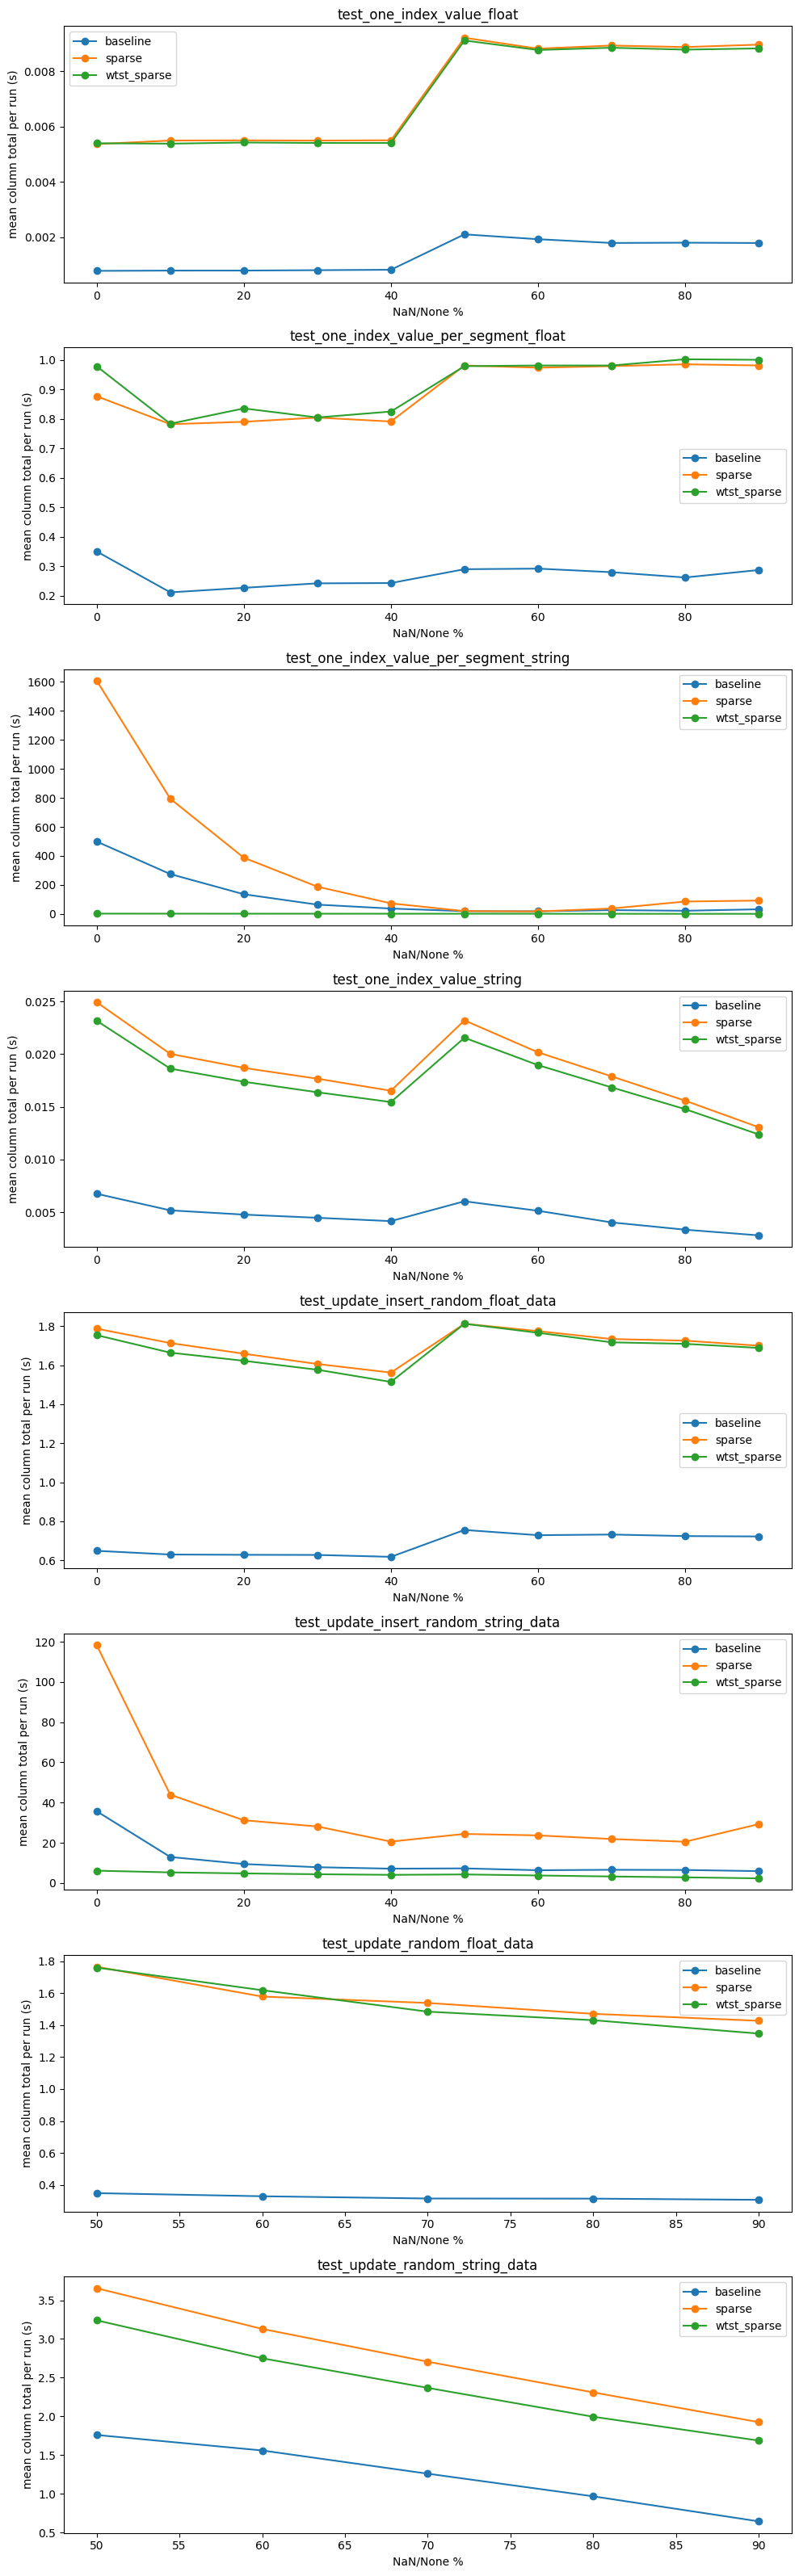

In [27]:
fig, axes = plt.subplots(len(TESTS), 1, figsize=(10, 4 * len(TESTS)))
for ax, test in zip(axes, TESTS):
    for suite in SUITES:
        df = nan_impact[(nan_impact["test"] == test) & (nan_impact["suite"] == suite)]
        ax.plot(df["nan_pct"], df["mean_total_s"], marker="o", label=suite)
    ax.set_title(test)
    ax.set_xlabel("NaN/None %")
    ax.set_ylabel("mean column total per run (s)")
    ax.legend()
fig.tight_layout()